# Step 01: Multi-Subject mmWave Radar Point Cloud Exploration & Noise Filtering Audit

Explores the TI IWR6843 4D mmWave point cloud properties across subjects and classes:
1. Inspects raw point cloud attributes: `x`, `y`, `z`, radial velocity `v`, Signal-to-Noise Ratio (`snr`), and `noise`.
2. Demonstrates noise filtering (`snr >= 100`, `|v| <= 3.0 m/s`).
3. Visualizes spatial point distributions and Doppler velocity profiles for Fall vs ADL (Non-Fall) events.


In [1]:
# Cell 1: System Imports & Setup
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path: sys.path.insert(0, str(root_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.dataset_parser import get_all_recording_files, extract_subject, extract_label, load_recording_df

sns.set_theme(style="whitegrid")
all_files = get_all_recording_files()
print(f"Discovered {len(all_files)} total CSV recording files.")


Discovered 102 total CSV recording files.


In [2]:
# Cell 2: Inspect Raw Point Cloud Attributes (Sample Fall vs Sample ADL)
fall_sample = next(f for f in all_files if extract_label(f) == 1)
adl_sample = next(f for f in all_files if extract_label(f) == 0)

df_fall_raw = pd.read_csv(fall_sample)
df_adl_raw = pd.read_csv(adl_sample)

print(f"Sample Fall Recording: {fall_sample.name} ({len(df_fall_raw)} total points)")
print(df_fall_raw.head())

print(f"\nSample ADL Recording: {adl_sample.name} ({len(df_adl_raw)} total points)")
print(df_adl_raw.head())


Sample Fall Recording: Areeb_back_1.csv (238 total points)
   frame  DetObj#         x         y         z    v  snr  noise
0      0        0 -0.106953  0.039879 -0.008597  0.0  301    477
1      0        1 -0.432412  1.728784 -0.201075  0.0  179    548
2      0        2 -0.115003  1.902050 -0.093566  0.0  126    600
3      0        3 -0.569265  2.014436 -0.148715  0.0  136    663
4      0        4  0.667018  2.087541 -0.308129  0.0  116    641

Sample ADL Recording: Areeb_bow_1.csv (235 total points)
   frame  DetObj#         x         y         z    v  snr  noise
0      0        0 -0.106953  0.039868 -0.008649  0.0  271    507
1      0        1 -0.598016  1.398539 -0.126182  0.0  123    514
2      0        2 -0.486463  1.716810 -0.178952  0.0  174    554
3      0        3 -0.569265  2.014042 -0.153956  0.0  147    653
4      0        4  2.817576  2.427596 -0.388087  0.0  143    535


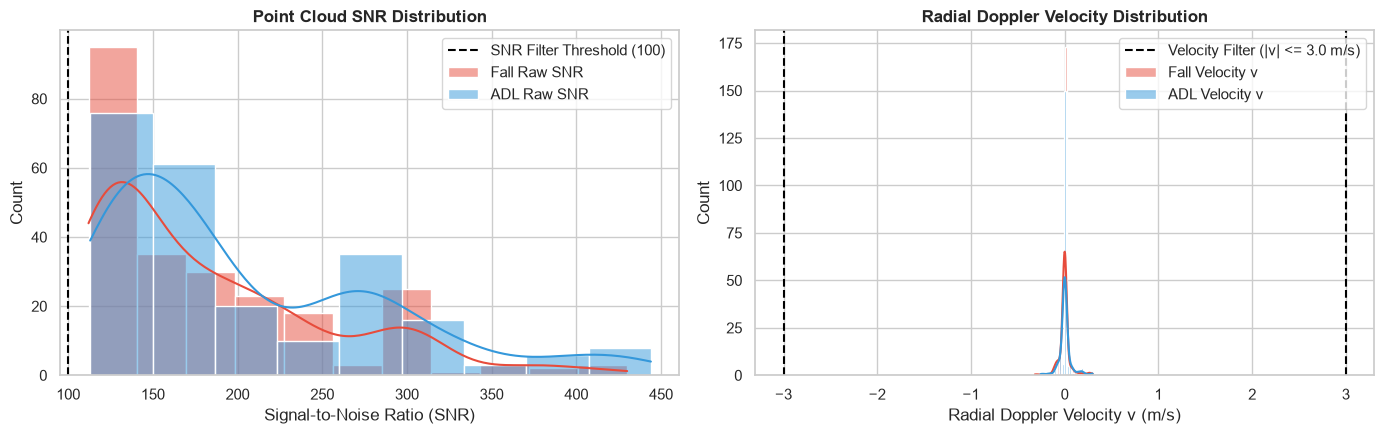

In [3]:
# Cell 3: Noise Filtering Analysis (SNR Distribution & Range Filtering)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=100)

sns.histplot(df_fall_raw["snr"], kde=True, color="#e74c3c", ax=axes[0], label="Fall Raw SNR")
sns.histplot(df_adl_raw["snr"], kde=True, color="#3498db", ax=axes[0], label="ADL Raw SNR")
axes[0].axvline(100, color="black", linestyle="--", label="SNR Filter Threshold (100)")
axes[0].set_title("Point Cloud SNR Distribution", fontweight="bold")
axes[0].set_xlabel("Signal-to-Noise Ratio (SNR)")
axes[0].legend()

sns.histplot(df_fall_raw["v"], kde=True, color="#e74c3c", ax=axes[1], label="Fall Velocity v")
sns.histplot(df_adl_raw["v"], kde=True, color="#3498db", ax=axes[1], label="ADL Velocity v")
axes[1].axvline(-3.0, color="black", linestyle="--")
axes[1].axvline(3.0, color="black", linestyle="--", label="Velocity Filter (|v| <= 3.0 m/s)")
axes[1].set_title("Radial Doppler Velocity Distribution", fontweight="bold")
axes[1].set_xlabel("Radial Doppler Velocity v (m/s)")
axes[1].legend()

plt.tight_layout()
plt.show()


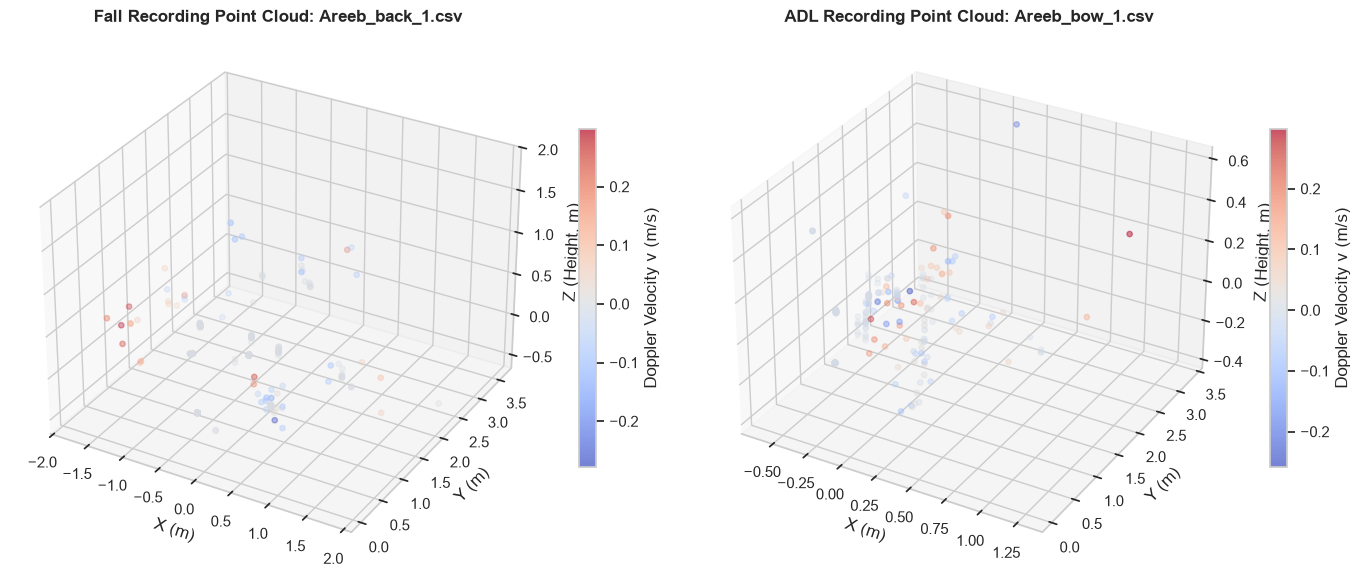

In [4]:
# Cell 4: 3D Point Cloud Spatial Trajectory (Fall vs ADL)
df_fall_clean = load_recording_df(fall_sample)
df_adl_clean = load_recording_df(adl_sample)

fig = plt.figure(figsize=(14, 6), dpi=100)

ax1 = fig.add_subplot(121, projection="3d")
sc1 = ax1.scatter(df_fall_clean["x"], df_fall_clean["y"], df_fall_clean["z"], c=df_fall_clean["v"], cmap="coolwarm", s=15, alpha=0.7)
ax1.set_title(f"Fall Recording Point Cloud: {fall_sample.name}", fontweight="bold")
ax1.set_xlabel("X (m)")
ax1.set_ylabel("Y (m)")
ax1.set_zlabel("Z (Height, m)")
fig.colorbar(sc1, ax=ax1, shrink=0.6, label="Doppler Velocity v (m/s)")

ax2 = fig.add_subplot(122, projection="3d")
sc2 = ax2.scatter(df_adl_clean["x"], df_adl_clean["y"], df_adl_clean["z"], c=df_adl_clean["v"], cmap="coolwarm", s=15, alpha=0.7)
ax2.set_title(f"ADL Recording Point Cloud: {adl_sample.name}", fontweight="bold")
ax2.set_xlabel("X (m)")
ax2.set_ylabel("Y (m)")
ax2.set_zlabel("Z (Height, m)")
fig.colorbar(sc2, ax=ax2, shrink=0.6, label="Doppler Velocity v (m/s)")

plt.tight_layout()
plt.show()
